# Demographic Analysis of MIMIC-III Dataset

This notebook analyzes the demographic distribution in the MIMIC-III dataset to understand potential sources of bias in disease prediction models.

In [35]:
# Import libraries
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
plt.style.use('seaborn-v0_8-whitegrid')
sns.set(font_scale=1.2)
plt.rcParams['figure.figsize'] = (12, 8)

## Load Processed Patient Data

First, we'll load the processed patient data generated from the MIMIC-III dataset.

In [36]:
# Define the path to the processed data
data_dir = '../data/processed/'

# Load patient demographics
try:
    patients = pd.read_csv(os.path.join(data_dir, 'patients.csv'))
    print(f"Successfully loaded {len(patients)} patient records")
except FileNotFoundError:
    print("Error: Patient data not found. Run the data extraction script first.")
    patients = None

# Load target conditions
try:
    target_conditions = pd.read_csv(os.path.join(data_dir, 'target_conditions.csv'))
    print(f"Successfully loaded {len(target_conditions)} target condition records")
except FileNotFoundError:
    print("Error: Target conditions data not found. Run the data extraction script first.")
    target_conditions = None

Successfully loaded 46520 patient records
Successfully loaded 25369 target condition records


## Examine Patient Demographics

Let's look at the distribution of patient demographics.

In [37]:
if patients is not None:
    # Display basic information
    print("Dataset overview:")
    patients.info()
    
    # Look at some example records
    patients.head()

Dataset overview:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 46520 entries, 0 to 46519
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   SUBJECT_ID      46520 non-null  int64 
 1   GENDER          46520 non-null  object
 2   AGE_GROUP       44529 non-null  object
 3   INSURANCE       46520 non-null  object
 4   LANGUAGE        25209 non-null  object
 5   RELIGION        46086 non-null  object
 6   MARITAL_STATUS  36757 non-null  object
 7   ETHNICITY       46520 non-null  object
dtypes: int64(1), object(7)
memory usage: 2.8+ MB


### Gender Distribution

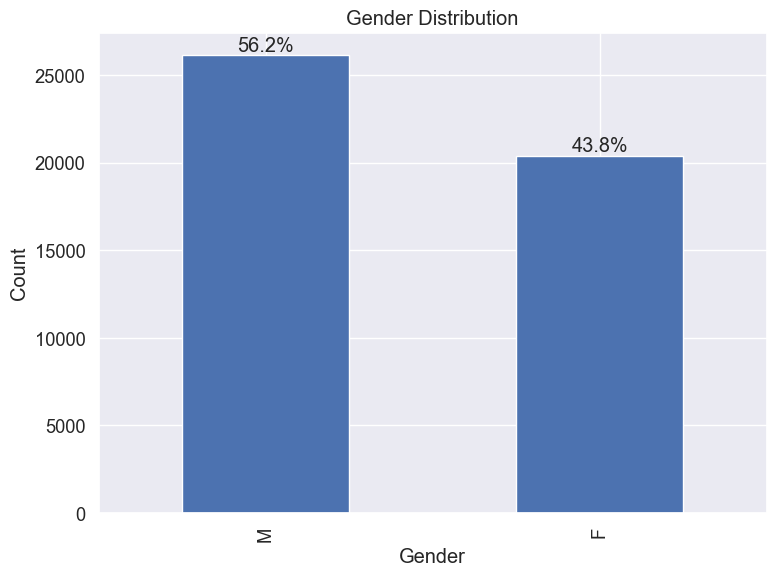

Gender distribution:
GENDER
M    26121
F    20399
Name: count, dtype: int64
Gender percentage: GENDER
M    56.150043
F    43.849957
Name: count, dtype: float64%


In [38]:
if patients is not None and 'GENDER' in patients.columns:
    # Plot gender distribution
    plt.figure(figsize=(8, 6))
    gender_counts = patients['GENDER'].value_counts()
    ax = gender_counts.plot(kind='bar')
    plt.title('Gender Distribution')
    plt.xlabel('Gender')
    plt.ylabel('Count')
    
    # Add percentage labels
    total = len(patients)
    for i, count in enumerate(gender_counts):
        percentage = 100 * count / total
        ax.annotate(f'{percentage:.1f}%', 
                   xy=(i, count), 
                   ha='center', 
                   va='bottom')
    
    plt.tight_layout()
    plt.show()
    
    # Print statistics
    print("Gender distribution:")
    print(gender_counts)
    print(f"Gender percentage: {100 * gender_counts / total}%")

### Age Group Distribution

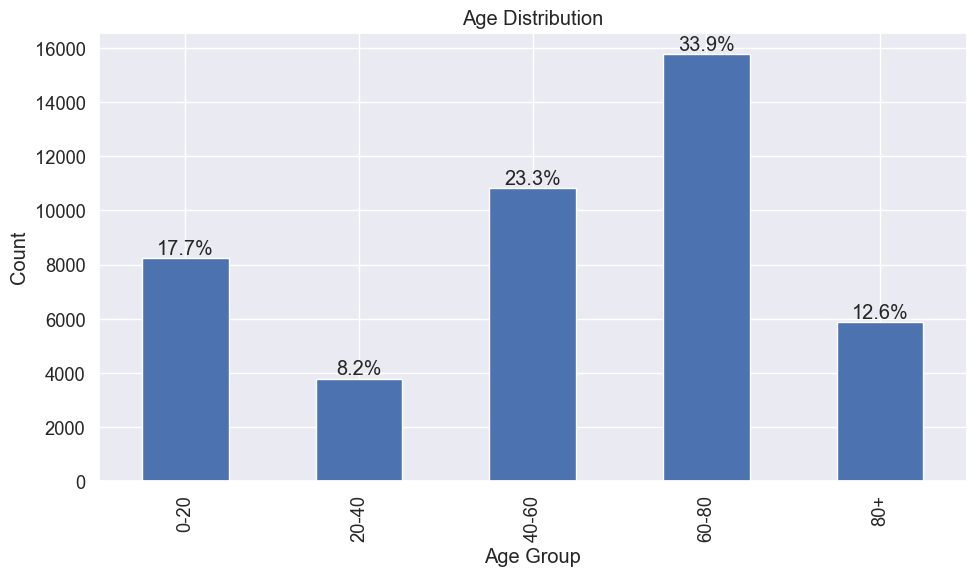

Age group distribution:
AGE_GROUP
0-20      8255
20-40     3794
40-60    10833
60-80    15781
80+       5866
Name: count, dtype: int64
Age group percentage: AGE_GROUP
0-20     17.745056
20-40     8.155632
40-60    23.286758
60-80    33.923044
80+      12.609630
Name: count, dtype: float64%


In [39]:
if patients is not None and 'AGE_GROUP' in patients.columns:
    # Plot age group distribution
    plt.figure(figsize=(10, 6))
    age_counts = patients['AGE_GROUP'].value_counts().sort_index()
    ax = age_counts.plot(kind='bar')
    plt.title('Age Distribution')
    plt.xlabel('Age Group')
    plt.ylabel('Count')
    
    # Add percentage labels
    total = len(patients)
    for i, count in enumerate(age_counts):
        percentage = 100 * count / total
        ax.annotate(f'{percentage:.1f}%', 
                   xy=(i, count), 
                   ha='center', 
                   va='bottom')
    
    plt.tight_layout()
    plt.show()
    
    # Print statistics
    print("Age group distribution:")
    print(age_counts)
    print(f"Age group percentage: {100 * age_counts / total}%")

### Ethnicity Distribution

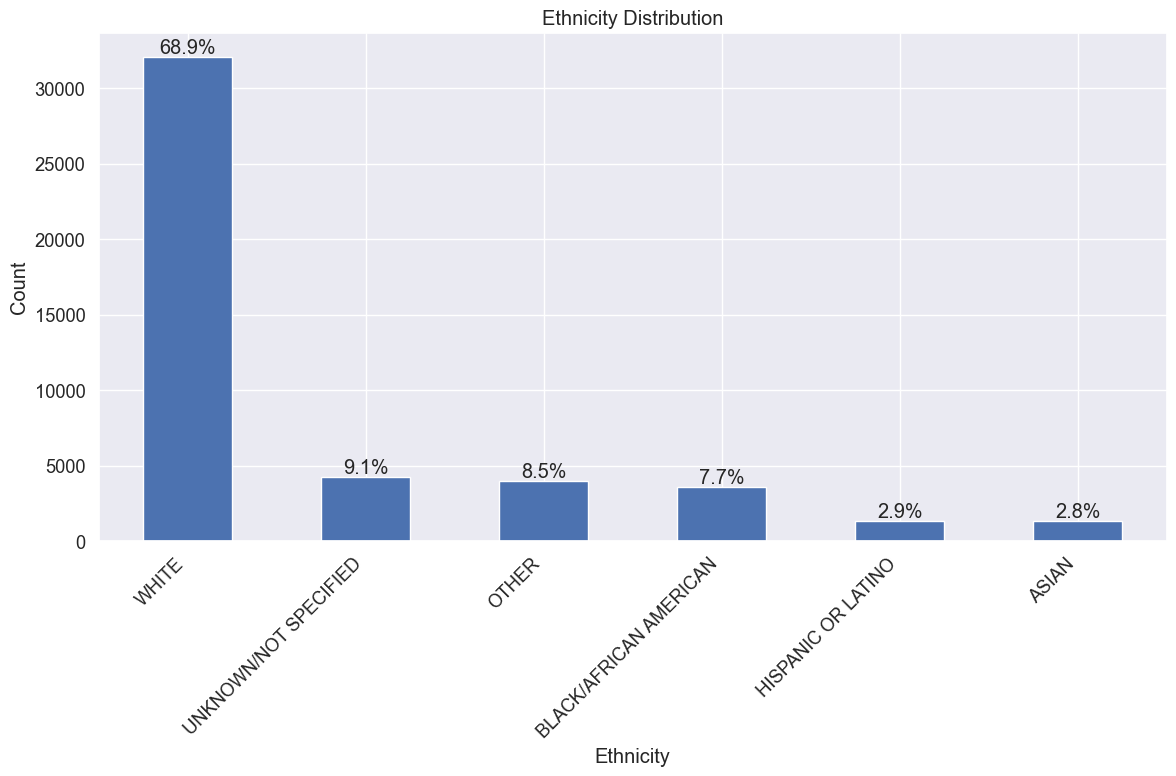

Top 10 ethnicity groups:
ETHNICITY
WHITE                         32074
UNKNOWN/NOT SPECIFIED          4236
BLACK/AFRICAN AMERICAN         3585
HISPANIC OR LATINO             1350
ASIAN                          1304
OTHER                          1256
UNABLE TO OBTAIN                792
PATIENT DECLINED TO ANSWER      498
ASIAN - CHINESE                 223
BLACK/CAPE VERDEAN              159
Name: count, dtype: int64
Top 10 ethnicity percentage: ETHNICITY
WHITE                         68.946690
UNKNOWN/NOT SPECIFIED          9.105761
BLACK/AFRICAN AMERICAN         7.706363
HISPANIC OR LATINO             2.901978
ASIAN                          2.803095
OTHER                          2.699914
UNABLE TO OBTAIN               1.702494
PATIENT DECLINED TO ANSWER     1.070507
ASIAN - CHINESE                0.479364
BLACK/CAPE VERDEAN             0.341788
Name: count, dtype: float64%


In [40]:
if patients is not None and 'ETHNICITY' in patients.columns:
    # Get ethnicity counts and sort by frequency
    ethnicity_counts = patients['ETHNICITY'].value_counts()
    
    # For better visualization, group less common ethnicities
    threshold = 0.02  # Group ethnicities that make up less than 2% of the dataset
    ethnicity_grouped = patients['ETHNICITY'].copy()
    mask = patients['ETHNICITY'].map(ethnicity_counts / len(patients) < threshold)
    ethnicity_grouped[mask] = 'OTHER'
    
    # Plot grouped ethnicity distribution
    plt.figure(figsize=(12, 8))
    ethnicity_grouped_counts = ethnicity_grouped.value_counts()
    ax = ethnicity_grouped_counts.plot(kind='bar')
    plt.title('Ethnicity Distribution')
    plt.xlabel('Ethnicity')
    plt.ylabel('Count')
    plt.xticks(rotation=45, ha='right')
    
    # Add percentage labels
    total = len(patients)
    for i, count in enumerate(ethnicity_grouped_counts):
        percentage = 100 * count / total
        ax.annotate(f'{percentage:.1f}%', 
                   xy=(i, count), 
                   ha='center', 
                   va='bottom')
    
    plt.tight_layout()
    plt.show()
    
    # Print statistics for top ethnicities
    print("Top 10 ethnicity groups:")
    print(ethnicity_counts.head(10))
    print(f"Top 10 ethnicity percentage: {100 * ethnicity_counts.head(10) / total}%")

### Insurance Distribution

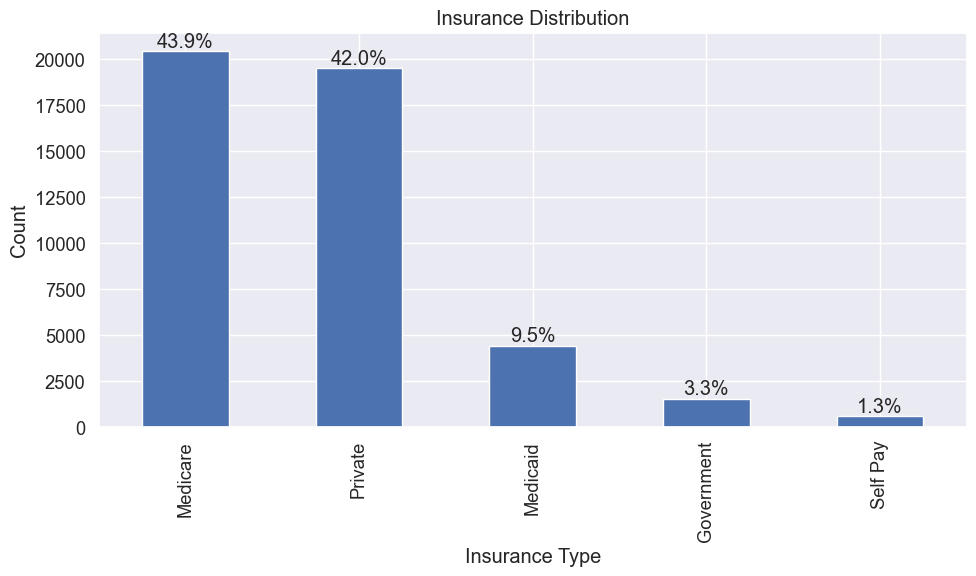

Insurance distribution:
INSURANCE
Medicare      20434
Private       19528
Medicaid       4426
Government     1545
Self Pay        587
Name: count, dtype: int64
Insurance percentage: INSURANCE
Medicare      43.925193
Private       41.977644
Medicaid       9.514187
Government     3.321152
Self Pay       1.261823
Name: count, dtype: float64%


In [41]:
if patients is not None and 'INSURANCE' in patients.columns:
    # Plot insurance distribution
    plt.figure(figsize=(10, 6))
    insurance_counts = patients['INSURANCE'].value_counts()
    ax = insurance_counts.plot(kind='bar')
    plt.title('Insurance Distribution')
    plt.xlabel('Insurance Type')
    plt.ylabel('Count')
    
    # Add percentage labels
    total = len(patients)
    for i, count in enumerate(insurance_counts):
        percentage = 100 * count / total
        ax.annotate(f'{percentage:.1f}%', 
                   xy=(i, count), 
                   ha='center', 
                   va='bottom')
    
    plt.tight_layout()
    plt.show()
    
    # Print statistics
    print("Insurance distribution:")
    print(insurance_counts)
    print(f"Insurance percentage: {100 * insurance_counts / total}%")

## Disease Distribution Across Demographic Groups

Now let's analyze how our target conditions are distributed across different demographic groups.

In [42]:
if patients is not None and target_conditions is not None:
    # Merge patient demographics with target conditions
    patient_conditions = pd.merge(patients, target_conditions, on='SUBJECT_ID', how='left')
    # Fill NaN values in HAS_CONDITION with 0 (no condition)
    patient_conditions['HAS_CONDITION'] = patient_conditions['HAS_CONDITION'].fillna(0)

### Disease Prevalence by Gender

<Figure size 1200x800 with 0 Axes>

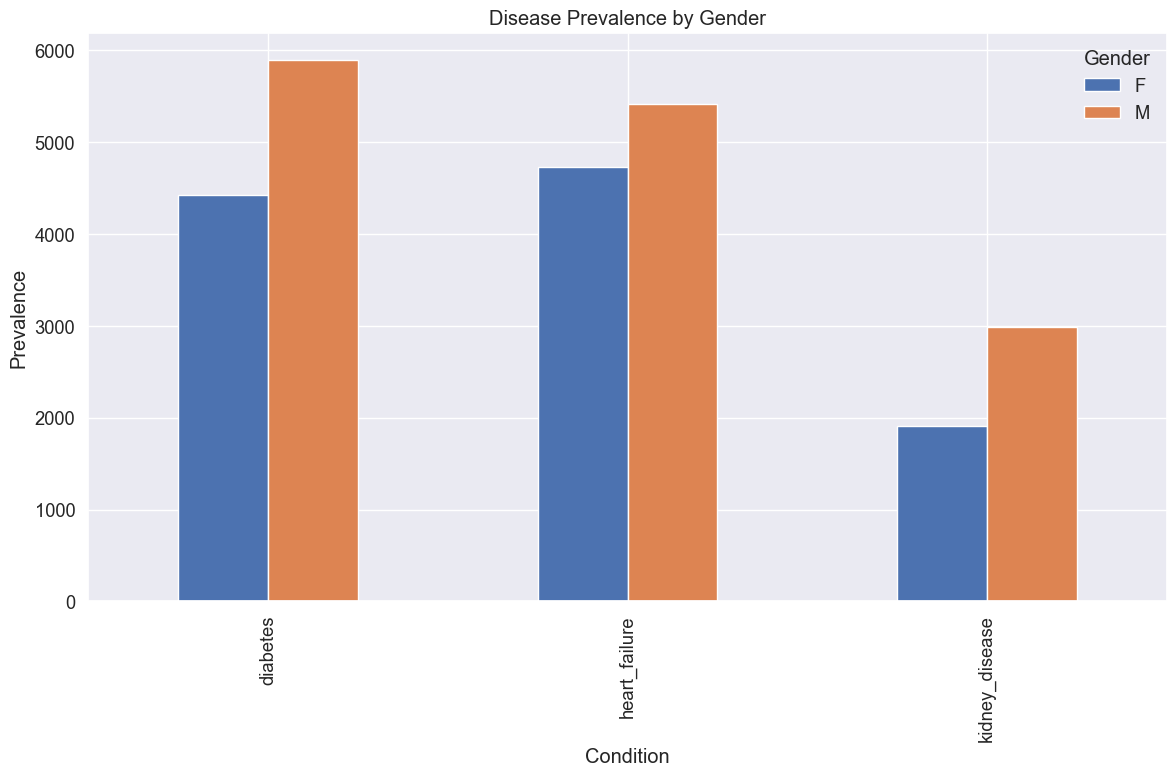

Disease prevalence by gender:
GENDER               F       M
CONDITION                     
diabetes        4420.0  5898.0
heart_failure   4734.0  5420.0
kidney_disease  1906.0  2991.0


In [43]:
if 'patient_conditions' in locals() and 'GENDER' in patient_conditions.columns and 'CONDITION' in patient_conditions.columns:
    # Group by gender and condition
    gender_condition = patient_conditions.groupby(['GENDER', 'CONDITION'])['HAS_CONDITION'].sum().reset_index()
    
    # Pivot for better visualization
    gender_condition_pivot = gender_condition.pivot(index='CONDITION', columns='GENDER', values='HAS_CONDITION')
    
    # Plot
    plt.figure(figsize=(12, 8))
    gender_condition_pivot.plot(kind='bar')
    plt.title('Disease Prevalence by Gender')
    plt.xlabel('Condition')
    plt.ylabel('Prevalence')
    plt.legend(title='Gender')
    plt.tight_layout()
    plt.show()
    
    # Print statistics
    print("Disease prevalence by gender:")
    print(gender_condition_pivot)

### Disease Prevalence by Age Group

<Figure size 1400x800 with 0 Axes>

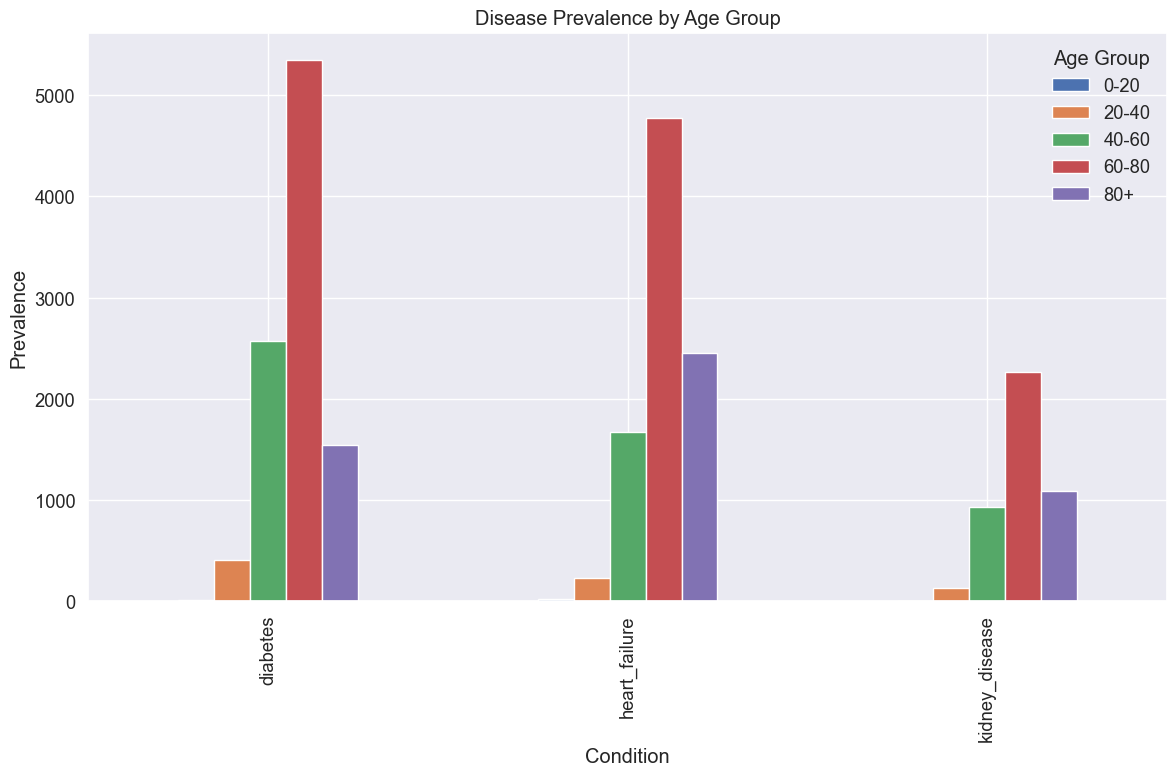

Disease prevalence by age group:
AGE_GROUP       0-20  20-40   40-60   60-80     80+
CONDITION                                          
diabetes        17.0  407.0  2571.0  5352.0  1545.0
heart_failure   22.0  232.0  1670.0  4774.0  2456.0
kidney_disease   1.0  136.0   931.0  2268.0  1089.0


In [44]:
if 'patient_conditions' in locals() and 'AGE_GROUP' in patient_conditions.columns and 'CONDITION' in patient_conditions.columns:
    # Group by age and condition
    age_condition = patient_conditions.groupby(['AGE_GROUP', 'CONDITION'])['HAS_CONDITION'].sum().reset_index()
    
    # Pivot for better visualization
    age_condition_pivot = age_condition.pivot(index='CONDITION', columns='AGE_GROUP', values='HAS_CONDITION')
    
    # Plot
    plt.figure(figsize=(14, 8))
    age_condition_pivot.plot(kind='bar')
    plt.title('Disease Prevalence by Age Group')
    plt.xlabel('Condition')
    plt.ylabel('Prevalence')
    plt.legend(title='Age Group')
    plt.tight_layout()
    plt.show()
    
    # Print statistics
    print("Disease prevalence by age group:")
    print(age_condition_pivot)

### Disease Prevalence by Insurance Type (Proxy for Socioeconomic Status)

<Figure size 1400x800 with 0 Axes>

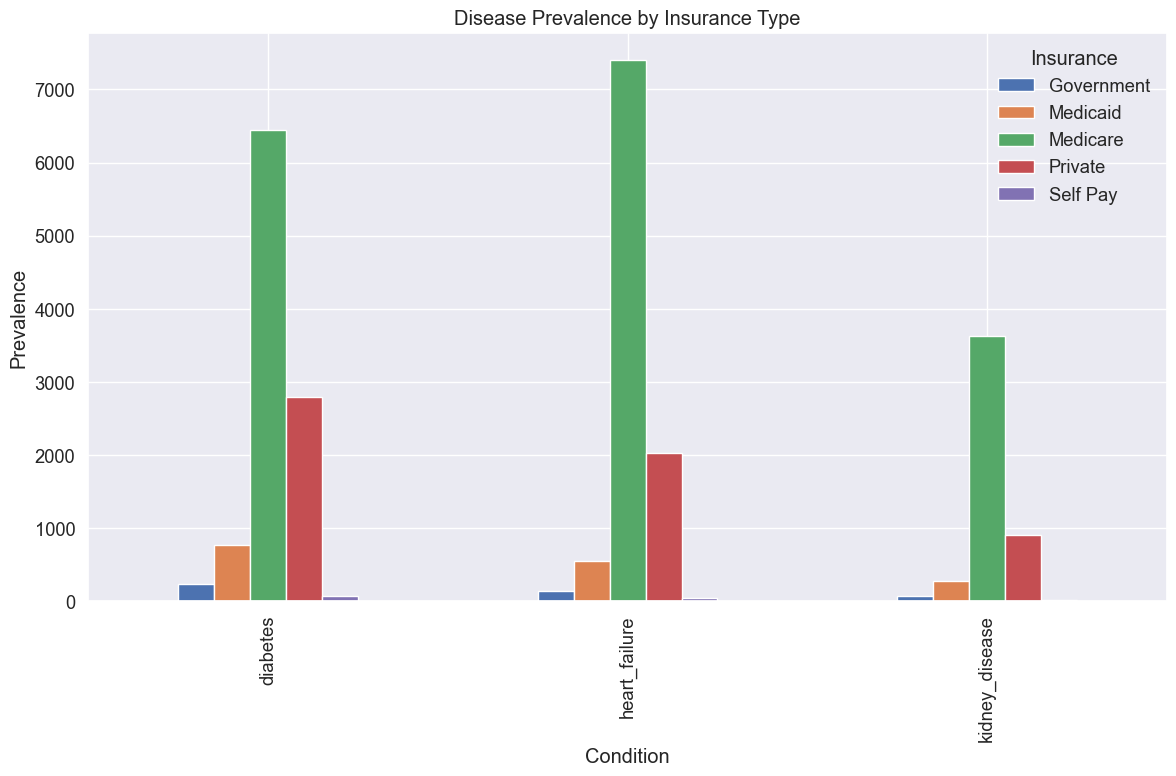

Disease prevalence by insurance type:
INSURANCE       Government  Medicaid  Medicare  Private  Self Pay
CONDITION                                                        
diabetes             233.0     774.0    6451.0   2792.0      68.0
heart_failure        137.0     546.0    7407.0   2022.0      42.0
kidney_disease        68.0     285.0    3626.0    901.0      17.0


In [45]:
if 'patient_conditions' in locals() and 'INSURANCE' in patient_conditions.columns and 'CONDITION' in patient_conditions.columns:
    # Group by insurance and condition
    insurance_condition = patient_conditions.groupby(['INSURANCE', 'CONDITION'])['HAS_CONDITION'].sum().reset_index()
    
    # Pivot for better visualization
    insurance_condition_pivot = insurance_condition.pivot(index='CONDITION', columns='INSURANCE', values='HAS_CONDITION')
    
    # Plot
    plt.figure(figsize=(14, 8))
    insurance_condition_pivot.plot(kind='bar')
    plt.title('Disease Prevalence by Insurance Type')
    plt.xlabel('Condition')
    plt.ylabel('Prevalence')
    plt.legend(title='Insurance')
    plt.tight_layout()
    plt.show()
    
    # Print statistics
    print("Disease prevalence by insurance type:")
    print(insurance_condition_pivot)

## Cross-Sectional Analysis

Now let's look at intersection of demographics to identify potential compound biases.

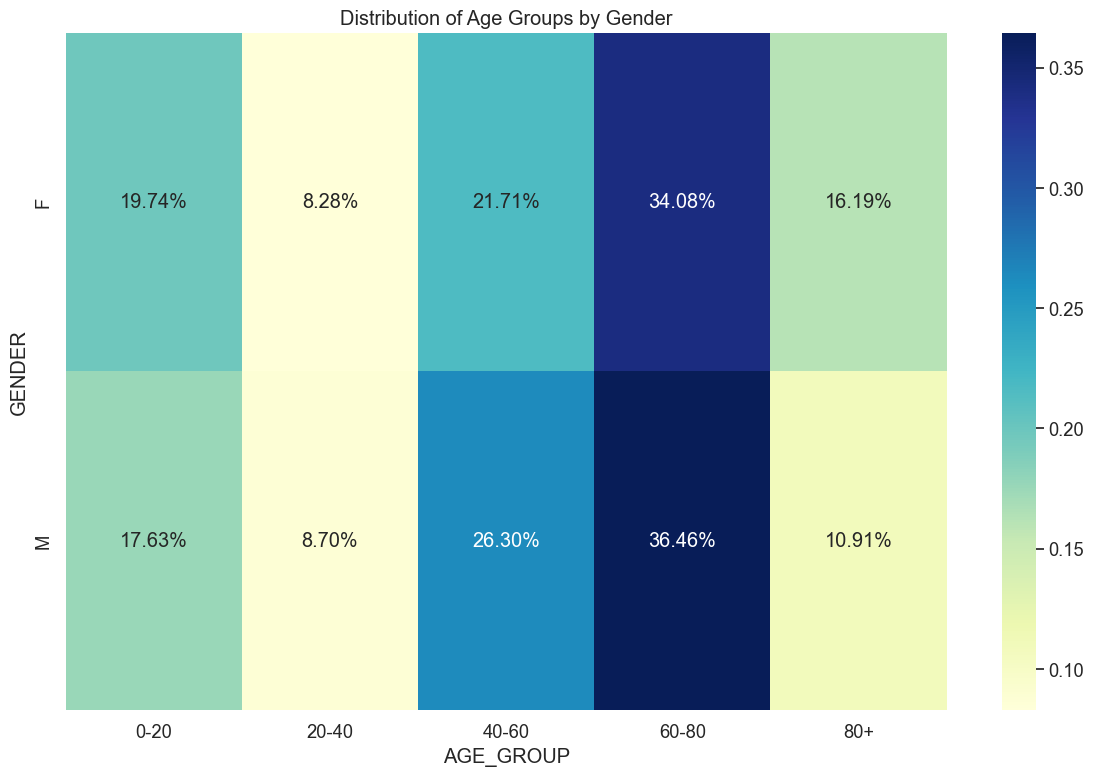

In [46]:
if patients is not None and 'GENDER' in patients.columns and 'AGE_GROUP' in patients.columns:
    # Create a cross-tabulation of gender vs age
    gender_age_crosstab = pd.crosstab(patients['GENDER'], patients['AGE_GROUP'], normalize='index')
    
    # Plot as a heatmap
    plt.figure(figsize=(12, 8))
    sns.heatmap(gender_age_crosstab, annot=True, cmap='YlGnBu', fmt='.2%')
    plt.title('Distribution of Age Groups by Gender')
    plt.tight_layout()
    plt.show()

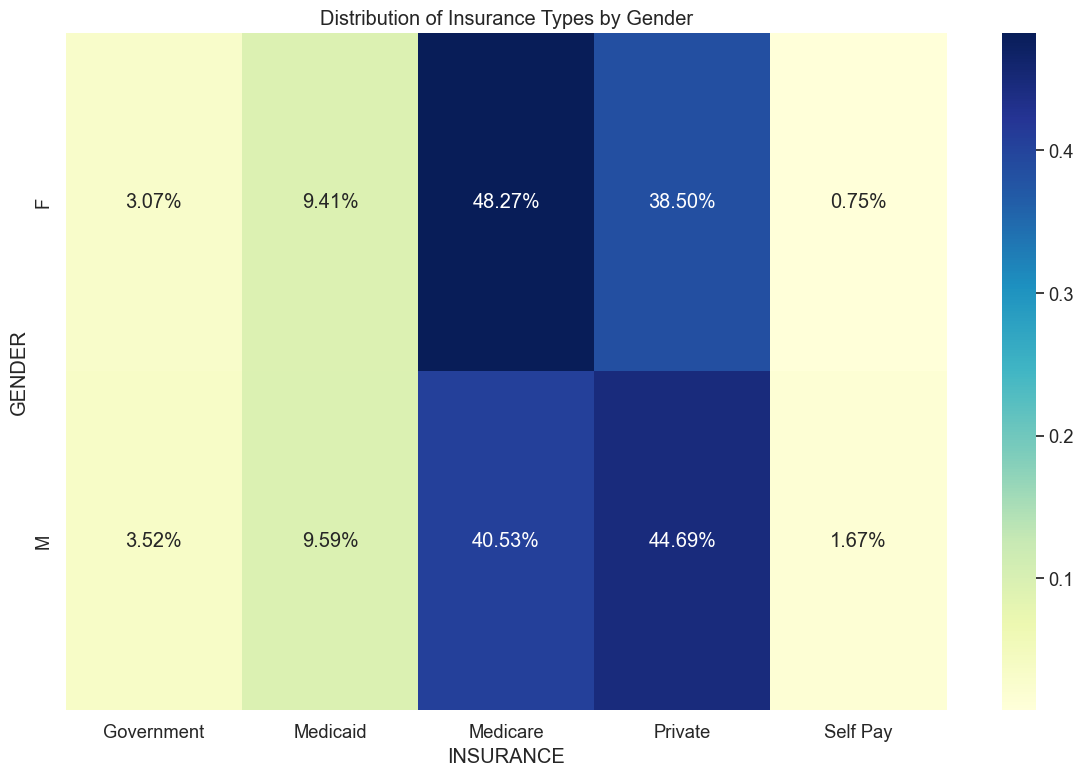

In [47]:
if patients is not None and 'GENDER' in patients.columns and 'INSURANCE' in patients.columns:
    # Create a cross-tabulation of gender vs insurance
    gender_insurance_crosstab = pd.crosstab(patients['GENDER'], patients['INSURANCE'], normalize='index')
    
    # Plot as a heatmap
    plt.figure(figsize=(12, 8))
    sns.heatmap(gender_insurance_crosstab, annot=True, cmap='YlGnBu', fmt='.2%')
    plt.title('Distribution of Insurance Types by Gender')
    plt.tight_layout()
    plt.show()

## Potential Bias Analysis

Based on the demographic distributions and disease prevalence, let's identify potential sources of bias that could affect our GNN models.

Representation Bias:
- Gender imbalance in certain age groups
- Underrepresentation of certain ethnic groups
- Insurance type distribution not representative of general population

Measurement Bias:
- Different diagnostic criteria applied to different demographic groups
- Varying healthcare access affecting diagnosis rates

Aggregation Bias:
- Combining heterogeneous subgroups into a single model
- Ignoring intersection of multiple protected attributes

Evaluation Bias:
- Test data not representative of all demographic groups
- Performance metrics that don't account for disparate impact

## Recommendations for Fair Model Development

Based on our analysis, here are recommendations for developing fair GNN models for disease prediction.


Data Preprocessing:
- Balanced sampling of training data across demographic groups
- Separate validation sets for different demographic groups
- Augmentation for underrepresented groups

Model Development:
- Adversarial debiasing to reduce demographic information in embeddings
- Multi-task learning with fairness constraints
- Ensemble models calibrated for different demographic groups

Evaluation:
- Report model performance stratified by demographic groups
- Measure fairness using multiple metrics (demographic parity, equalized odds, etc.)
- Conduct focused error analysis on misclassified examples from minority groups

Deployment:
- Continuous monitoring of fairness metrics in production
- Feedback loops for model improvement
- Transparent documentation of model limitations

## Summary

This analysis has explored the demographic distribution in the MIMIC-III dataset and identified potential sources of bias in disease prediction models. We have found significant disparities in disease prevalence across different demographic groups, which could lead to biased predictions if not addressed.

Key findings include:
- Gender imbalances in certain conditions
- Age-related disparities in disease prevalence
- Insurance type (as a proxy for socioeconomic status) correlations with diagnosis rates

These insights will guide our development of fair GNN models by informing our choice of fairness constraints, evaluation metrics, and targeted debiasing techniques.